# **8. 뉴스 요약봇 만들기 [프로젝트]**

## **8-1. 프로젝트: 뉴스기사 요약해보기**

새로운 데이터셋에 대해서 추상적 요약과 추출적 요약을 모두 해보는 시간을 가져봐요.<br>
<br>
먼저 주요 라이브러리 버전을 확인해 보죠.

In [44]:
# Step 0. 필요한 라이브러리 설치

%pip install -q summa rouge-score sentencepiece

In [45]:
import os
import re
import html
import time
import copy
import random
import urllib.request

from collections import Counter
from importlib.metadata import version

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

from sklearn.model_selection import train_test_split
from rouge_score import rouge_scorer

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Summa:", version("summa"))
print("ROUGE:", version("rouge-score"))
print("Device:", DEVICE)

PyTorch: 2.14.1+cu130
Pandas: 2.2.3
Summa: 1.2.0
ROUGE: 0.1.2
Device: cuda


### **Step 1. 데이터 수집하기**

데이터는 아래 링크에 있는 뉴스 기사 데이터(`news_summary_more.csv`)를 사용하세요.<br>
<br>
- [sunnysai12345/News_Summary](https://github.com/sunnysai12345/News_Summary)<br><br>

아래의 코드로 데이터를 다운로드할 수 있어요.

In [46]:
import urllib.request
# Step 1-1. 뉴스 데이터 다운로드

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "sunnysai12345/News_Summary/master/"
    "news_summary_more.csv"
)

DATA_PATH = "/content/news_summary_more.csv"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# 인코딩 차이에 대응
try:
    data = pd.read_csv(DATA_PATH, encoding="utf-8")

except UnicodeDecodeError:
    data = pd.read_csv(DATA_PATH, encoding="iso-8859-1")

assert {"text", "headlines"}.issubset(data.columns)

print("전체 데이터 크기:", data.shape)

display(data.sample(5, random_state=SEED))

전체 데이터 크기: (98401, 2)


,headlines,text
32571,K'taka students to get extra marks if parents ...,Students in Karnataka will get extra marks if ...
35184,Syria shoots down missiles fired at two air bases,Syrian anti-aircraft defences on Monday shot d...
59997,Dinosaur-like animal's fossil found in Uttarak...,A Dinosaur-like creature's fossil was found du...
64665,"UP may merge Shia, Sunni Waqf boards to preven...",The Uttar Pradesh government is planning to fo...
15343,Egypt actress gets 2 yrs jail for 'fake news' ...,Egyptian activist-actress Amal Fathy has been ...


In [47]:
data.sample(10)

,headlines,text
32571,K'taka students to get extra marks if parents ...,Students in Karnataka will get extra marks if ...
35184,Syria shoots down missiles fired at two air bases,Syrian anti-aircraft defences on Monday shot d...
59997,Dinosaur-like animal's fossil found in Uttarak...,A Dinosaur-like creature's fossil was found du...
64665,"UP may merge Shia, Sunni Waqf boards to preven...",The Uttar Pradesh government is planning to fo...
15343,Egypt actress gets 2 yrs jail for 'fake news' ...,Egyptian activist-actress Amal Fathy has been ...
52898,Jeff Bezos added more wealth in 2017 than GDP ...,World's richest person and Amazon CEO Jeff Bez...
95149,Bangladeshi captain Mortaza announces retireme...,Bangladesh cricket team's limited overs captai...
76915,Mexican drug lord El Chapo questions US extrad...,Mexican drug lord Joaquin 'El Chapo' Guzman ha...
49398,N Korea supplies ballistic missiles to Myanmar...,Independent United Nations (UN) monitors have ...
74036,Thenga mila hamme: Harbhajan responds to home ...,After reports of three Amrapali Group companie...


In [48]:
# Step 1-2. 데이터 품질 분석

print("전체 샘플 수:", len(data))

print("\n결측값:")
print(data[["text", "headlines"]].isnull().sum())

print("\n중복 뉴스 수:")
print(data.duplicated(subset="text").sum())

print("\n뉴스 본문 길이:")
print(data["text"].dropna().str.split().str.len().describe())

print("\n헤드라인 길이:")
print(data["headlines"].dropna().str.split().str.len().describe())

전체 샘플 수: 98401

결측값:
text         0
headlines    0
dtype: int64

중복 뉴스 수:
41

뉴스 본문 길이:
count    98401.000000
mean        58.237701
std          2.381343
min          1.000000
25%         57.000000
50%         59.000000
75%         60.000000
max         66.000000
Name: text, dtype: float64

헤드라인 길이:
count    98401.000000
mean         9.553876
std          1.457956
min          1.000000
25%          9.000000
50%         10.000000
75%         10.000000
max         18.000000
Name: headlines, dtype: float64


이 데이터는 기사의 본문에 해당되는 text와 headlines 두 가지 열로 구성되어져 있습니다.<br>
<br>
추상적 요약을 하는 경우에는 text를 본문, headlines를 이미 요약된 데이터로 삼아서 모델을 학습할 수 있어요. 추출적 요약을 하는 경우에는 오직 text열만을 사용하세요.

### **Step 2. 데이터 전처리하기 (추상적 요약)**

실습에서 사용된 전처리를 참고하여 각자 필요하다고 생각하는 전처리를 추가 사용하여 텍스트를 정규화 또는 정제해 보세요. 만약, 불용어 제거를 선택한다면 상대적으로 길이가 짧은 요약 데이터에 대해서도 불용어를 제거하는 것이 좋을지 고민해 보세요.

In [49]:
# Step 2-1. 정규화 및 불용어 처리

from nltk.corpus import stopwords

# 영어 불용어 준비
nltk.download("stopwords", quiet=True)

try:
    stop_words = set(stopwords.words("english"))

except LookupError:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    stop_words = set(ENGLISH_STOP_WORDS)

# 뉴스에서 중요한 표현은 유지
important_words = {
    "no", "not", "nor", "never",
    "against", "without", "before", "after",
    "over", "under", "more", "less",
    "us", "may", "will", "can"
}

stop_words -= important_words

contractions = {
    "can't": "cannot",
    "won't": "will not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not"
}

def normalize_text(text):

    text = html.unescape(str(text))

    # HTML 태그 제거
    text = re.sub(r"<[^>]+>", " ", text)

    # 소문자 및 아포스트로피 통일
    text = text.lower()
    text = text.replace("’", "'")

    # 주요 축약어 정규화
    for old, new in contractions.items():
        text = re.sub(
            r"\b" + re.escape(old) + r"\b",
            new,
            text
        )

    # 영문, 숫자, 일부 숫자 단위 보존
    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?|"
        r"\d+(?:[.,:/-]\d+)*%?|[$£€%]",
        text
    )

    return tokens


def preprocess(text, remove_stopwords=False):

    tokens = normalize_text(text)

    if remove_stopwords:
        tokens = [
            word for word in tokens
            if word not in stop_words
        ]

    return tokens


sample = "The company didn't reduce its revenue by 20% in 2025."

print("원본:", sample)
print("정규화:", normalize_text(sample))
print("불용어 제거:", preprocess(sample, True))

원본: The company didn't reduce its revenue by 20% in 2025.
정규화: ['the', 'company', 'did', 'not', 'reduce', 'its', 'revenue', 'by', '20%', 'in', '2025']
불용어 제거: ['company', 'not', 'reduce', 'revenue', '20%', '2025']


In [50]:
# Step 2-2. 데이터 정제 및 분리

RUN_MODE = "final"

clean_data = data[["text", "headlines"]].dropna().copy()

clean_data["text"] = (
    clean_data["text"].astype(str).str.strip()
)

clean_data["headlines"] = (
    clean_data["headlines"].astype(str).str.strip()
)

clean_data = clean_data[
    (clean_data["text"].str.len() > 0) &
    (clean_data["headlines"].str.len() > 0)
].copy()

# 정규화된 원문 기준으로 중복 제거
clean_data["normalized_text"] = clean_data["text"].map(
    lambda x: " ".join(normalize_text(x))
)

clean_data = clean_data.drop_duplicates(
    subset="normalized_text"
)

# 본문: 불용어 제거
clean_data["src_tokens"] = clean_data["text"].map(
    lambda x: preprocess(x, True)
)

# 헤드라인: 불용어 유지
clean_data["tgt_tokens"] = clean_data["headlines"].map(
    lambda x: preprocess(x, False)
)

# 전처리 후 빈 문장 제거
clean_data = clean_data[
    (clean_data["src_tokens"].map(len) > 0) &
    (clean_data["tgt_tokens"].map(len) > 0)
].copy()

print("전처리 후 전체 데이터:", len(clean_data))

# 실험 규모 설정
N_SAMPLES = 6000 if RUN_MODE == "quick" else 30000

sampled_data = clean_data.sample(
    n=min(N_SAMPLES, len(clean_data)),
    random_state=SEED
).reset_index(drop=True)

# Train 80%, Validation 10%, Test 10%
train_df, remaining_df = train_test_split(
    sampled_data,
    test_size=0.2,
    random_state=SEED
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.5,
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

display(train_df.head(3))

전처리 후 전체 데이터: 98339
Train: 24000
Validation: 3000
Test: 3000


,text,headlines,normalized_text,src_tokens,tgt_tokens
0,A video which shows a guard at an ATM in Goa's...,Goa ATM guard fights robber attacking him with...,a video which shows a guard at an atm in goa's...,"[video, shows, guard, atm, goa's, panaji, hit,...","[goa, atm, guard, fights, robber, attacking, h..."
1,Technology major Microsoft has added a 'Quiet ...,Microsoft adds 'do not disturb' feature to Win...,technology major microsoft has added a quiet h...,"[technology, major, microsoft, added, quiet, h...","[microsoft, adds, do, not, disturb, feature, t..."
2,While hearing a case involving two boys who we...,Boys swapped at birth to decide to return when...,while hearing a case involving two boys who we...,"[hearing, case, involving, two, boys, swapped,...","[boys, swapped, at, birth, to, decide, to, ret..."


본문 평균 길이: 38.222
헤드라인 평균 길이: 9.87425
Encoder 최대 길이: 45
요약 최대 단어 수: 13
본문 잘림 비율: 0.04066666666666666
요약 잘림 비율: 0.015833333333333335


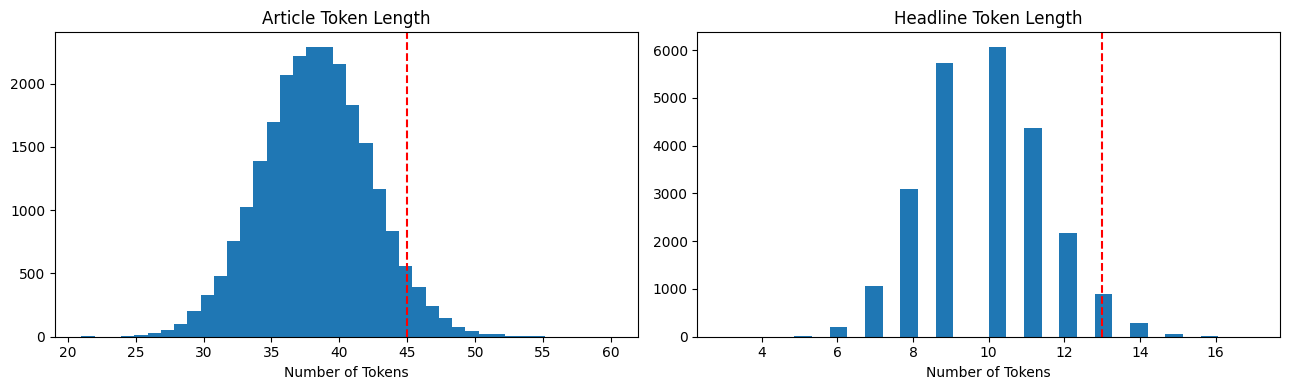

In [51]:
# Step 2-3. 입력 및 출력 길이 분석

src_lengths = train_df["src_tokens"].map(len).to_numpy()
tgt_lengths = train_df["tgt_tokens"].map(len).to_numpy()

SRC_MAX_LEN = min(
    96,
    max(24, int(np.ceil(np.percentile(src_lengths, 95))))
)

TGT_MAX_LEN = min(
    20,
    max(8, int(np.ceil(np.percentile(tgt_lengths, 95))))
)

print("본문 평균 길이:", src_lengths.mean())
print("헤드라인 평균 길이:", tgt_lengths.mean())

print("Encoder 최대 길이:", SRC_MAX_LEN)
print("요약 최대 단어 수:", TGT_MAX_LEN)

print(
    "본문 잘림 비율:",
    np.mean(src_lengths > SRC_MAX_LEN)
)

print(
    "요약 잘림 비율:",
    np.mean(tgt_lengths > TGT_MAX_LEN)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(src_lengths, bins=40)
axes[0].axvline(
    SRC_MAX_LEN,
    color="red",
    linestyle="--"
)
axes[0].set_title("Article Token Length")
axes[0].set_xlabel("Number of Tokens")

axes[1].hist(tgt_lengths, bins=30)
axes[1].axvline(
    TGT_MAX_LEN,
    color="red",
    linestyle="--"
)
axes[1].set_title("Headline Token Length")
axes[1].set_xlabel("Number of Tokens")

plt.tight_layout()
plt.show()

In [52]:
# Step 2-4. Vocabulary 생성

PAD = 0
UNK = 1
BOS = 2
EOS = 3

SPECIAL_TOKENS = {
    "<PAD>": PAD,
    "<UNK>": UNK,
    "<BOS>": BOS,
    "<EOS>": EOS
}

def build_vocab(sentences, max_size):

    counter = Counter(
        token
        for sentence in sentences
        for token in sentence
    )

    vocab = SPECIAL_TOKENS.copy()

    for word, count in counter.most_common(max_size - 4):

        if word not in vocab:
            vocab[word] = len(vocab)

    return vocab


# 학습 데이터만 활용
src_vocab = build_vocab(
    train_df["src_tokens"],
    max_size=16000
)

tgt_vocab = build_vocab(
    train_df["tgt_tokens"],
    max_size=8000
)

src_index_to_word = {
    idx: word for word, idx in src_vocab.items()
}

tgt_index_to_word = {
    idx: word for word, idx in tgt_vocab.items()
}

print("본문 단어사전:", len(src_vocab))
print("요약 단어사전:", len(tgt_vocab))

본문 단어사전: 16000
요약 단어사전: 8000


In [53]:
# Step 2-5. Tensor 데이터 생성

def pad_ids(ids, max_len):

    ids = ids[:max_len]

    return ids + [PAD] * (max_len - len(ids))


def encode_source(tokens):

    ids = [
        src_vocab.get(word, UNK)
        for word in tokens
    ]

    return pad_ids(ids, SRC_MAX_LEN)


def encode_target(tokens):

    ids = [
        tgt_vocab.get(word, UNK)
        for word in tokens[:TGT_MAX_LEN]
    ]

    decoder_input = [BOS] + ids
    decoder_target = ids + [EOS]

    return (
        pad_ids(decoder_input, TGT_MAX_LEN + 1),
        pad_ids(decoder_target, TGT_MAX_LEN + 1)
    )


def make_dataset(df):

    sources = []
    decoder_inputs = []
    decoder_targets = []

    for src, tgt in zip(
        df["src_tokens"],
        df["tgt_tokens"]
    ):

        sources.append(encode_source(src))

        dec_in, dec_out = encode_target(tgt)

        decoder_inputs.append(dec_in)
        decoder_targets.append(dec_out)

    return TensorDataset(
        torch.tensor(sources, dtype=torch.long),
        torch.tensor(decoder_inputs, dtype=torch.long),
        torch.tensor(decoder_targets, dtype=torch.long)
    )


train_dataset = make_dataset(train_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    src, dec_in, dec_out = dataset.tensors

    print(name)
    print("Encoder:", src.shape)
    print("Decoder Input:", dec_in.shape)
    print("Decoder Target:", dec_out.shape)

    assert src.max().item() < len(src_vocab)
    assert dec_in.max().item() < len(tgt_vocab)
    assert dec_out.max().item() < len(tgt_vocab)

    assert (src != PAD).any(dim=1).all().item()
    assert dec_in.shape == dec_out.shape

print("\n모든 Tensor 검증 완료!")

Train
Encoder: torch.Size([24000, 45])
Decoder Input: torch.Size([24000, 14])
Decoder Target: torch.Size([24000, 14])
Validation
Encoder: torch.Size([3000, 45])
Decoder Input: torch.Size([3000, 14])
Decoder Target: torch.Size([3000, 14])
Test
Encoder: torch.Size([3000, 45])
Decoder Input: torch.Size([3000, 14])
Decoder Target: torch.Size([3000, 14])

모든 Tensor 검증 완료!


In [55]:
# Step 2-6. SentencePiece 기반 토큰화 개선

import sentencepiece as spm

# 이전 단어 기반 실험 결과 보존
if "result_df" in globals():
    word_baseline_result = result_df.copy()

# Train 데이터만 이용하여 SentencePiece 학습
sp_corpus = (
    [" ".join(tokens) for tokens in train_df["src_tokens"]]
    + [" ".join(tokens) for tokens in train_df["tgt_tokens"]]
)

spm.SentencePieceTrainer.train(
    sentence_iterator=iter(sp_corpus),
    model_prefix="/content/news_spm",
    vocab_size=8000,
    model_type="bpe",
    character_coverage=1.0,
    byte_fallback=True,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3,
    hard_vocab_limit=False
)

sp = spm.SentencePieceProcessor(
    model_file="/content/news_spm.model"
)

# 기존 특수 토큰 ID 유지
PAD = sp.pad_id()
UNK = sp.unk_id()
BOS = sp.bos_id()
EOS = sp.eos_id()

# Encoder와 Decoder에서 동일한 Vocabulary 사용
src_vocab = {
    sp.id_to_piece(i): i
    for i in range(sp.get_piece_size())
}

tgt_vocab = src_vocab.copy()

src_index_to_word = {
    idx: word for word, idx in src_vocab.items()
}

tgt_index_to_word = src_index_to_word.copy()

print("SentencePiece Vocabulary:", sp.get_piece_size())

sample = "Priyanka meets Syrian refugee"

print("원본:", sample)
print("서브워드:", sp.encode(sample, out_type=str))
print("정수 ID:", sp.encode(sample, out_type=int))

SentencePiece Vocabulary: 8000
원본: Priyanka meets Syrian refugee
서브워드: ['▁', '<0x50>', 'ri', 'y', 'anka', '▁meets', '▁', '<0x53>', 'y', 'ri', 'an', '▁refug', 'ee']
정수 ID: [7954, 84, 361, 7972, 1297, 6544, 7954, 87, 7972, 361, 267, 4376, 481]


In [72]:
# Step 2-7. SentencePiece Tensor 생성
def analyze_unk(tensor, name):

    valid_mask = (
        (tensor != PAD) &
        (tensor != BOS) &
        (tensor != EOS)
    )

    total_tokens = valid_mask.sum().item()
    unk_tokens = (tensor == UNK).sum().item()

    unk_rate = unk_tokens / max(total_tokens, 1)

    print(f"{name}")
    print(f"전체 일반 토큰 수: {total_tokens:,}")
    print(f"UNK 토큰 수: {unk_tokens:,}")
    print(f"UNK 비율: {unk_rate * 100:.2f}%")
    print()

def sp_encode(tokens):
    return sp.encode(
        " ".join(tokens),
        out_type=int
    )


# 서브워드 길이 분포 재분석
src_lengths = np.array([
    len(sp_encode(tokens))
    for tokens in train_df["src_tokens"]
])

tgt_lengths = np.array([
    len(sp_encode(tokens))
    for tokens in train_df["tgt_tokens"]
])

SRC_MAX_LEN = min(
    128,
    max(32, int(np.ceil(np.percentile(src_lengths, 95))))
)

TGT_MAX_LEN = min(
    32,
    max(16, int(np.ceil(np.percentile(tgt_lengths, 95))))
)

print("Source Max Length:", SRC_MAX_LEN)
print("Target Max Length:", TGT_MAX_LEN)


# Encoder 입력
def encode_source(tokens):

    ids = sp_encode(tokens)

    return pad_ids(ids, SRC_MAX_LEN)


# Decoder 입력 및 정답
def encode_target(tokens):

    ids = sp_encode(tokens)[:TGT_MAX_LEN]

    decoder_input = [BOS] + ids
    decoder_target = ids + [EOS]

    return (
        pad_ids(decoder_input, TGT_MAX_LEN + 1),
        pad_ids(decoder_target, TGT_MAX_LEN + 1)
    )


# 기존 데이터셋 생성 함수 재사용
train_dataset = make_dataset(train_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    src, dec_in, dec_out = dataset.tensors

    print("\n", name)
    print("Encoder Shape:", src.shape)
    print("Decoder Shape:", dec_in.shape)

    analyze_unk(src, f"{name} Encoder")
    analyze_unk(dec_out, f"{name} Decoder")

    assert src.max().item() < len(src_vocab)
    assert dec_in.max().item() < len(tgt_vocab)
    assert dec_out.max().item() < len(tgt_vocab)

print("SentencePiece 데이터 생성 완료!")

Source Max Length: 68
Target Max Length: 17

 Train
Encoder Shape: torch.Size([24000, 68])
Decoder Shape: torch.Size([24000, 18])
Train Encoder
전체 일반 토큰 수: 1,251,484
UNK 토큰 수: 0
UNK 비율: 0.00%

Train Decoder
전체 일반 토큰 수: 305,157
UNK 토큰 수: 0
UNK 비율: 0.00%


 Validation
Encoder Shape: torch.Size([3000, 68])
Decoder Shape: torch.Size([3000, 18])
Validation Encoder
전체 일반 토큰 수: 157,629
UNK 토큰 수: 0
UNK 비율: 0.00%

Validation Decoder
전체 일반 토큰 수: 38,412
UNK 토큰 수: 0
UNK 비율: 0.00%


 Test
Encoder Shape: torch.Size([3000, 68])
Decoder Shape: torch.Size([3000, 18])
Test Encoder
전체 일반 토큰 수: 157,729
UNK 토큰 수: 0
UNK 비율: 0.00%

Test Decoder
전체 일반 토큰 수: 38,406
UNK 토큰 수: 0
UNK 비율: 0.00%

SentencePiece 데이터 생성 완료!


In [73]:
# 추가 분석: UNK 토큰 발생 비율 확인

def analyze_unk(tensor, name):

    valid_mask = (
        (tensor != PAD) &
        (tensor != BOS) &
        (tensor != EOS)
    )

    total_tokens = valid_mask.sum().item()
    unk_tokens = (tensor == UNK).sum().item()

    unk_rate = unk_tokens / max(total_tokens, 1)

    print(f"{name}")
    print(f"전체 일반 토큰 수: {total_tokens:,}")
    print(f"UNK 토큰 수: {unk_tokens:,}")
    print(f"UNK 비율: {unk_rate * 100:.2f}%")
    print()


for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    src, dec_in, dec_out = dataset.tensors

    analyze_unk(src, f"{name} - Encoder")
    analyze_unk(dec_out, f"{name} - Decoder Target")


# 학습 정답에서 자주 등장하는 토큰 확인
target_ids = train_dataset.tensors[2].flatten().tolist()

token_counter = Counter(
    idx for idx in target_ids
    if idx not in [PAD, BOS, EOS]
)

print("=== Decoder 학습 정답 빈도 상위 15개 ===")

for idx, count in token_counter.most_common(15):

    print(
        tgt_index_to_word.get(idx, "<UNK>"),
        ":", count
    )

Train - Encoder
전체 일반 토큰 수: 1,251,484
UNK 토큰 수: 0
UNK 비율: 0.00%

Train - Decoder Target
전체 일반 토큰 수: 305,157
UNK 토큰 수: 0
UNK 비율: 0.00%

Validation - Encoder
전체 일반 토큰 수: 157,629
UNK 토큰 수: 0
UNK 비율: 0.00%

Validation - Decoder Target
전체 일반 토큰 수: 38,412
UNK 토큰 수: 0
UNK 비율: 0.00%

Test - Encoder
전체 일반 토큰 수: 157,729
UNK 토큰 수: 0
UNK 비율: 0.00%

Test - Decoder Target
전체 일반 토큰 수: 38,406
UNK 토큰 수: 0
UNK 비율: 0.00%

=== Decoder 학습 정답 빈도 상위 15개 ===
▁to : 7762
▁in : 6632
s : 6604
' : 5042
▁for : 3722
▁of : 3219
▁on : 3126
▁with : 1432
▁a : 1423
▁india : 1418
▁not : 1293
▁at : 1261
▁after : 1230
▁over : 1131
▁from : 1131


### **Step 3. 어텐션 메커니즘 사용하기 (추상적 요약)**

일반적인 seq2seq보다는 어텐션 메커니즘을 사용한 seq2seq를 사용하는 것이 더 나은 성능을 얻을 수 있어요. 실습 내용을 참고하여 어텐션 메커니즘을 사용한 seq2seq를 설계해 보세요.

In [75]:
# Step 3-1. Seq2Seq Attention 모델

class NewsSeq2Seq(nn.Module):

    def __init__(
        self,
        src_size,
        tgt_size,
        use_attention=True
    ):

        super().__init__()

        self.use_attention = use_attention

        self.src_emb = nn.Embedding(
            src_size, 96, padding_idx=PAD
        )

        self.tgt_emb = nn.Embedding(
            tgt_size, 96, padding_idx=PAD
        )

        self.encoder = nn.LSTM(
            96, 128, batch_first=True
        )

        self.decoder = nn.LSTM(
            96, 128, batch_first=True
        )

        self.dropout = nn.Dropout(0.2)

        self.proj = nn.Linear(
            256 if use_attention else 128,
            128
        )

        self.output = nn.Linear(128, tgt_size)

    def encode(self, src):

        mask = src.ne(PAD)

        lengths = mask.sum(dim=1).cpu()

        # Padding을 제외하고 Encoder 학습
        packed = pack_padded_sequence(
            self.dropout(self.src_emb(src)),
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_out, state = self.encoder(packed)

        enc, _ = pad_packed_sequence(
            packed_out,
            batch_first=True,
            total_length=src.size(1)
        )

        return enc, state, mask

    def decode(self, tgt, state, enc, mask):

        dec, state = self.decoder(
            self.dropout(self.tgt_emb(tgt)),
            state
        )

        weights = None

        if self.use_attention:

            # Decoder와 Encoder의 관련성 계산
            scores = torch.bmm(
                dec,
                enc.transpose(1, 2)
            ) / (enc.size(-1) ** 0.5)

            # Padding 위치는 Attention에서 제외
            scores = scores.masked_fill(
                ~mask.unsqueeze(1),
                float("-inf")
            )

            weights = scores.softmax(dim=-1)

            # Encoder 상태의 가중합
            context = torch.bmm(weights, enc)

            # Decoder와 Context 결합
            dec = torch.cat(
                [dec, context],
                dim=-1
            )

        logits = self.output(
            self.dropout(
                torch.tanh(self.proj(dec))
            )
        )

        return logits, state, weights

    def forward(self, src, tgt):

        enc, state, mask = self.encode(src)

        logits, _, _ = self.decode(
            tgt, state, enc, mask
        )

        return logits

In [76]:
# Step 3-2. 모델 Forward 테스트

model = NewsSeq2Seq(
    len(src_vocab),
    len(tgt_vocab),
    use_attention=True
).to(DEVICE)

src, dec_in, dec_out = train_dataset.tensors

with torch.no_grad():

    output = model(
        src[:4].to(DEVICE),
        dec_in[:4].to(DEVICE)
    )

print("입력 크기:", src[:4].shape)
print("Decoder 입력:", dec_in[:4].shape)
print("출력 크기:", output.shape)

assert output.shape == (
    4,
    TGT_MAX_LEN + 1,
    len(tgt_vocab)
)

print("모델 구조 검증 완료!")

print(
    "전체 파라미터 수:",
    sum(p.numel() for p in model.parameters())
)

del model, output

입력 크기: torch.Size([4, 68])
Decoder 입력: torch.Size([4, 18])
출력 크기: torch.Size([4, 18, 8000])
모델 구조 검증 완료!
전체 파라미터 수: 2832320


In [77]:
# Step 3-3. 공통 학습 함수

BATCH_SIZE = 64
EPOCHS = 3 if RUN_MODE == "quick" else 20
LEARNING_RATE = 0.001
PATIENCE = 3


def run_epoch(model, loader, optimizer=None):

    is_train = optimizer is not None

    model.train(is_train)

    total_loss = 0
    total_tokens = 0

    with torch.set_grad_enabled(is_train):

        for src, dec_in, target in loader:

            src = src.to(DEVICE)
            dec_in = dec_in.to(DEVICE)
            target = target.to(DEVICE)

            if is_train:
                optimizer.zero_grad()

            logits = model(src, dec_in)

            loss_sum = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                target.reshape(-1),
                ignore_index=PAD,
                reduction="sum"
            )

            token_count = target.ne(PAD).sum().item()

            loss = loss_sum / max(token_count, 1)

            if is_train:

                loss.backward()

                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

            total_loss += loss_sum.item()
            total_tokens += token_count

    return total_loss / max(total_tokens, 1)


def train_model(use_attention=True):

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = NewsSeq2Seq(
        len(src_vocab),
        len(tgt_vocab),
        use_attention=use_attention
    ).to(DEVICE)

    generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    patience_count = 0
    history = []

    start = time.perf_counter()

    for epoch in range(EPOCHS):

        train_loss = run_epoch(
            model, train_loader, optimizer
        )

        val_loss = run_epoch(
            model, val_loader
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}",
            flush=True
        )

        if val_loss < best_loss:

            best_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            patience_count = 0

        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            print("Early Stopping")
            break

    # Validation Loss가 가장 낮은 모델 복원
    model.load_state_dict(best_state)

    elapsed = time.perf_counter() - start

    print("Best Epoch:", best_epoch)
    print("Best Validation Loss:", best_loss)
    print(f"Training Time: {elapsed:.2f} sec")

    return model, history

In [78]:
# Step 3-4. Attention 모델 학습

models = {}
histories = {}

print("Attention Seq2Seq 학습 시작")

models["Attention"], histories["Attention"] = train_model(
    use_attention=True
)

print("\nAttention 모델 학습 완료!")

Attention Seq2Seq 학습 시작
Epoch 1/20 | Train Loss: 7.2539 | Val Loss: 6.9243
Epoch 2/20 | Train Loss: 6.8116 | Val Loss: 6.6445
Epoch 3/20 | Train Loss: 6.5096 | Val Loss: 6.3593
Epoch 4/20 | Train Loss: 6.2370 | Val Loss: 6.1418
Epoch 5/20 | Train Loss: 5.9988 | Val Loss: 5.9587
Epoch 6/20 | Train Loss: 5.7975 | Val Loss: 5.8167
Epoch 7/20 | Train Loss: 5.6293 | Val Loss: 5.7064
Epoch 8/20 | Train Loss: 5.4881 | Val Loss: 5.6182
Epoch 9/20 | Train Loss: 5.3681 | Val Loss: 5.5583
Epoch 10/20 | Train Loss: 5.2592 | Val Loss: 5.4863
Epoch 11/20 | Train Loss: 5.1633 | Val Loss: 5.4503
Epoch 12/20 | Train Loss: 5.0749 | Val Loss: 5.3907
Epoch 13/20 | Train Loss: 4.9949 | Val Loss: 5.3523
Epoch 14/20 | Train Loss: 4.9200 | Val Loss: 5.3198
Epoch 15/20 | Train Loss: 4.8484 | Val Loss: 5.2805
Epoch 16/20 | Train Loss: 4.7831 | Val Loss: 5.2603
Epoch 17/20 | Train Loss: 4.7180 | Val Loss: 5.2417
Epoch 18/20 | Train Loss: 4.6630 | Val Loss: 5.2167
Epoch 19/20 | Train Loss: 4.6070 | Val Loss: 5.19

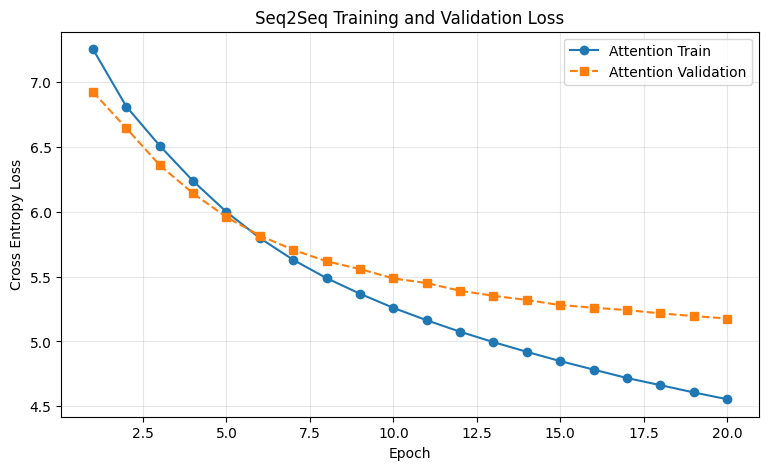

In [79]:
# Step 3-5. 모델 학습 곡선

plt.figure(figsize=(9, 5))

for name, history in histories.items():

    epochs = [row["epoch"] for row in history]

    plt.plot(
        epochs,
        [row["train_loss"] for row in history],
        marker="o",
        label=f"{name} Train"
    )

    plt.plot(
        epochs,
        [row["val_loss"] for row in history],
        marker="s",
        linestyle="--",
        label=f"{name} Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Seq2Seq Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [80]:
# 추가 실험: Attention Ablation Study

RUN_ABLATION = False

if RUN_ABLATION:

    models["No Attention"], histories["No Attention"] = train_model(
        use_attention=False
    )

else:
    print("Attention 미적용 비교 실험 생략")

Attention 미적용 비교 실험 생략


### **Step 4. 실제 결과와 요약문 비교하기 (추상적 요약)**

원래의 요약문(headlines 열)과 학습을 통해 얻은 추상적 요약의 결과를 비교해 보세요.

In [81]:
# Step 4-1. SentencePiece Greedy Decoding

@torch.inference_mode()
def generate(model, src, return_ids=False):

    model.eval()

    src = src.to(DEVICE)

    enc, state, mask = model.encode(src)

    token = torch.full(
        (len(src), 1),
        BOS,
        dtype=torch.long,
        device=DEVICE
    )

    ended = torch.zeros(
        len(src),
        dtype=torch.bool,
        device=DEVICE
    )

    sequences = [[] for _ in range(len(src))]
    attention_maps = [[] for _ in range(len(src))]

    for _ in range(TGT_MAX_LEN):

        logits, state, weights = model.decode(
            token, state, enc, mask
        )

        scores = logits[:, 0, :].clone()

        scores[:, PAD] = float("-inf")
        scores[:, BOS] = float("-inf")

        next_ids = scores.argmax(dim=1)

        for i, idx in enumerate(next_ids.tolist()):

            if not ended[i].item() and idx != EOS:

                sequences[i].append(idx)

                if weights is not None:

                    attention_maps[i].append(
                        weights[i, 0].cpu().numpy()
                    )

        ended |= next_ids.eq(EOS)

        if ended.all().item():
            break

        token = torch.where(
            ended,
            torch.full_like(next_ids, EOS),
            next_ids
        ).unsqueeze(1)

    # SentencePiece를 이용한 문장 복원
    summaries = [
        sp.decode(sequence)
        for sequence in sequences
    ]

    if return_ids:
        return summaries, attention_maps, sequences

    return summaries, attention_maps

In [82]:
# Step 4-2. 요약 결과 비교

X_test = test_dataset.tensors[0]

generated, attention_maps = generate(
    models["Attention"],
    X_test[:5]
)

for i, summary in enumerate(generated):

    print("=" * 70)

    print("원본 기사:")
    print(test_df.iloc[i]["text"])

    print("\n실제 헤드라인:")
    print(test_df.iloc[i]["headlines"])

    print("\nAI 생성 요약:")
    print(summary)

    print()

원본 기사:
Priyanka Chopra took to Instagram to share a video of a Syrian refugee who is Katrina Kaif's "biggest" fan. "Who would think that what we do as entertainers would give people a sense of hope, relief and escape in such dire circumstances," wrote Priyanka. As a UNICEF Global Goodwill Ambassador, Priyanka is in Jordan interacting with children refugees from Syria.

실제 헤드라인:
Priyanka meets Syrian refugee who is Katrina's fan

AI 생성 요약:
priyanka's 1 st look of the year of the year of the theatres

원본 기사:
Singer Taylor Swift has released a new soundtrack, titled '...Ready For It?' from her upcoming album 'Reputation'. The song will serve as the album's opening track. Earlier, the video of 'Look What You Made Me Do', another song from the album was released. 'Reputation' will be out on November 10, three years after the release of her last album '1989'.

실제 헤드라인:
Taylor Swift releases song '...Ready For It?' from new album

AI 생성 요약:
aishwarya's filmfare badhaai hoist to be a song

원본 

### **Step 5. Summa을 이용해서 추출적 요약해보기**

추상적 요약은 추출적 요약과는 달리 문장의 표현력을 다양하게 가져갈 수 있지만, 추출적 요약에 비해서 난이도가 높아요. 반대로 말하면 추출적 요약은 추상적 요약에 비해 난이도가 낮고 기존 문장에서 문장을 꺼내오는 것이므로 잘못된 요약이 나올 가능성이 낮아요.<br>
<br>
Summa의 summarize를 사용하여 추출적 요약을 해보세요.

In [83]:
# Step 5-1. Extractive Summarization

from summa.summarizer import summarize


def lead1_summary(text):

    # 첫 문장 추출
    sentences = re.split(
        r"(?<=[.!?])\s+",
        str(text).strip()
    )

    return sentences[0] if sentences else ""


def extractive_summary(text):

    try:

        result = summarize(
            str(text),
            ratio=0.4
        ).strip()

        if result:

            return result, True, ""

        reason = "Empty Summa output"

    except Exception as e:

        reason = type(e).__name__

    # Summa가 결과를 생성하지 못하는 경우
    return lead1_summary(text), False, reason


# 예시 뉴스 5건
for i in range(5):

    article = test_df.iloc[i]["text"]

    summary, success, reason = extractive_summary(article)

    print("=" * 70)
    print("실제 헤드라인:", test_df.iloc[i]["headlines"])
    print("추출적 요약:", summary)
    print("Summa 성공 여부:", success)

    if not success:
        print("Lead-1 대체 사유:", reason)

    print()

실제 헤드라인: Priyanka meets Syrian refugee who is Katrina's fan
추출적 요약: As a UNICEF Global Goodwill Ambassador, Priyanka is in Jordan interacting with children refugees from Syria.
Summa 성공 여부: True

실제 헤드라인: Taylor Swift releases song '...Ready For It?' from new album
추출적 요약: Earlier, the video of 'Look What You Made Me Do', another song from the album was released.
Summa 성공 여부: True

실제 헤드라인: North Central Railway plans to replace coaches of 36 trains
추출적 요약: The North Central Railway authorities have announced plans to replace conventional coaches with Linke Hofmann Busch (LHB) coaches in all the 36 trains operated by the zone.
Summa 성공 여부: True

실제 헤드라인: Video: Horse throws off bikini-clad rider at US nightclub
추출적 요약: A video of a bikini-clad rider being thrown off a horse at a nightclub in US' Miami has surfaced online.
Summa 성공 여부: True

실제 헤드라인: I don't take FIFA team rankings too seriously: Sunil Chhetri
추출적 요약: "If after three years we are still in the top 100, I think that will 

In [84]:
# 추가 실험 1-1. 요약 결과 수집

N_EVAL = min(200, len(test_df))

eval_indices = np.random.default_rng(SEED).choice(
    len(test_df),
    size=N_EVAL,
    replace=False
)

X_eval = X_test[eval_indices.tolist()]

all_generated = {}

# 학습한 모델별 요약 생성
for name, model in models.items():

    summaries = []

    for start in range(0, N_EVAL, 32):

        batch = X_eval[start:start + 32]

        outputs, _ = generate(model, batch)

        summaries.extend(outputs)

    all_generated[name] = summaries


records = []

for pos, idx in enumerate(eval_indices):

    article = test_df.iloc[idx]["text"]
    reference = test_df.iloc[idx]["headlines"]

    extracted, success, reason = extractive_summary(article)

    row = {
        "Article": article,
        "Reference": reference,
        "Summa + Fallback": extracted,
        "Summa Success": success,
        "Fallback Reason": reason,
        "Lead-1": lead1_summary(article)
    }

    for name, summaries in all_generated.items():
        row[name] = summaries[pos]

    records.append(row)

comparison_df = pd.DataFrame(records)

print("평가 데이터 수:", len(comparison_df))

print(
    "Summa 자체 생성 성공률:",
    comparison_df["Summa Success"].mean()
)

display(comparison_df.head(3))

평가 데이터 수: 200
Summa 자체 생성 성공률: 0.735


,Article,Reference,Summa + Fallback,Summa Success,Fallback Reason,Lead-1,Attention
0,Prime Minister Narendra Modi advised a group o...,Use work as chance to transform governance: PM...,Prime Minister Narendra Modi advised a group o...,False,Empty Summa output,Prime Minister Narendra Modi advised a group o...,pm modi is the best pm modi on pm modi's pm modi
1,AIADMK faction leader O Panneerselvam on Sunda...,OPS offers â¹10K for getting TN CM to respond...,AIADMK faction leader O Panneerselvam on Sunda...,False,Empty Summa output,AIADMK faction leader O Panneerselvam on Sunda...,bjp leader's son's son's name in mp's son in
2,Madras High Court on Tuesday banned the use of...,"HC bans pics of living persons on banners, sig...",Madras High Court on Tuesday banned the use of...,True,,Madras High Court on Tuesday banned the use of...,hc bans use of drugs to be probed by hc


,Method,ROUGE-1,ROUGE-2,ROUGE-L,Average Words,Samples
0,Attention,0.1368,0.0198,0.1257,10.675,200
1,Summa + Fallback,0.3280,0.1321,0.2734,24.030,200
2,Lead-1,0.4028,0.1824,0.3435,25.595,200



Summa 성공 샘플에 대한 동일 조건 비교


,Method,ROUGE-1,ROUGE-2,ROUGE-L,Average Words,Samples
0,Attention,0.1397,0.0232,0.1290,10.6122,147
1,Summa (Successful Only),0.3136,0.1259,0.2658,21.4150,147
2,Lead-1,0.4154,0.1944,0.3612,23.5442,147


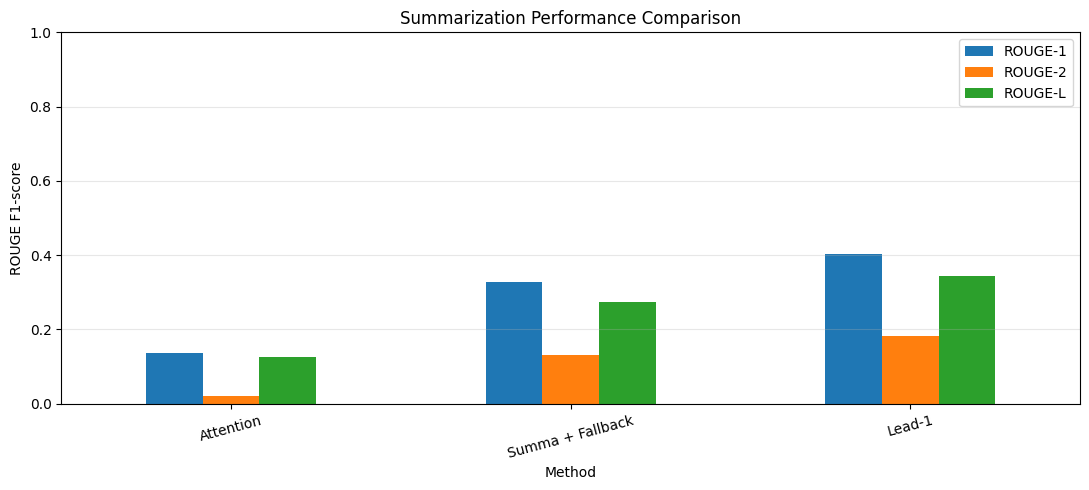

In [85]:
# 추가 실험 1-2. ROUGE 정량 평가

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

methods = list(models.keys()) + [
    "Summa + Fallback",
    "Lead-1"
]


def calculate_scores(df, methods):

    result_rows = []

    for method in methods:

        scores = []
        lengths = []

        for ref, pred in zip(
            df["Reference"],
            df[method]
        ):

            score = scorer.score(ref, pred)

            scores.append(score)
            lengths.append(len(pred.split()))

        result_rows.append({
            "Method": method,

            "ROUGE-1": np.mean([
                s["rouge1"].fmeasure for s in scores
            ]),

            "ROUGE-2": np.mean([
                s["rouge2"].fmeasure for s in scores
            ]),

            "ROUGE-L": np.mean([
                s["rougeL"].fmeasure for s in scores
            ]),

            "Average Words": np.mean(lengths),

            "Samples": len(df)
        })

    return pd.DataFrame(result_rows)


result_df = calculate_scores(comparison_df, methods)

display(result_df.round(4))

# Summa 자체 성공 샘플만 별도 비교
success_df = comparison_df[
    comparison_df["Summa Success"]
]

if len(success_df) > 0:

    print("\nSumma 성공 샘플에 대한 동일 조건 비교")

    pure_result_df = calculate_scores(
        success_df,
        methods
    ).rename(
        columns={"Method": "Method"}
    )

    pure_result_df["Method"] = pure_result_df["Method"].replace(
        "Summa + Fallback", "Summa (Successful Only)"
    )

    display(pure_result_df.round(4))

else:
    print("Summa 자체 요약 성공 샘플이 없습니다.")

# ROUGE 비교 그래프
result_df.set_index("Method")[
    ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=15
)

plt.title("Summarization Performance Comparison")
plt.ylabel("ROUGE F1-score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [88]:
# 최종 SentencePiece 모델의 생성 UNK 비율 검증

all_generated_ids = []

for start in range(0, len(X_eval), 32):

    batch = X_eval[start:start + 32]

    _, _, generated_ids = generate(
        models["Attention"],
        batch,
        return_ids=True
    )

    all_generated_ids.extend(generated_ids)

# 생성된 서브워드 ID 집계
generated_token_ids = [
    token_id
    for sequence in all_generated_ids
    for token_id in sequence
]

total_tokens = len(generated_token_ids)

unk_count = sum(
    token_id == UNK
    for token_id in generated_token_ids
)

unk_rate = unk_count / max(total_tokens, 1)

print("=== 최종 모델 UNK 발생 비율 ===")
print("평가 기사 수:", len(all_generated_ids))
print("전체 생성 토큰 수:", total_tokens)
print("생성된 UNK 수:", unk_count)
print(f"생성 UNK 비율: {unk_rate * 100:.2f}%")

print("\n기존 Word-level 모델: 56.90%")
print(f"개선 SentencePiece 모델: {unk_rate * 100:.2f}%")

=== 최종 모델 UNK 발생 비율 ===
평가 기사 수: 200
전체 생성 토큰 수: 2531
생성된 UNK 수: 0
생성 UNK 비율: 0.00%

기존 Word-level 모델: 56.90%
개선 SentencePiece 모델: 0.00%


원본 기사: Priyanka Chopra took to Instagram to share a video of a Syrian refugee who is Katrina Kaif's "biggest" fan. "Who would think that what we do as entertainers would give people a sense of hope, relief and escape in such dire circumstances," wrote Priyanka. As a UNICEF Global Goodwill Ambassador, Priyanka is in Jordan interacting with children refugees from Syria.
실제 헤드라인: Priyanka meets Syrian refugee who is Katrina's fan
생성 요약: priyanka's 1 st look of the year of the year of the theatres


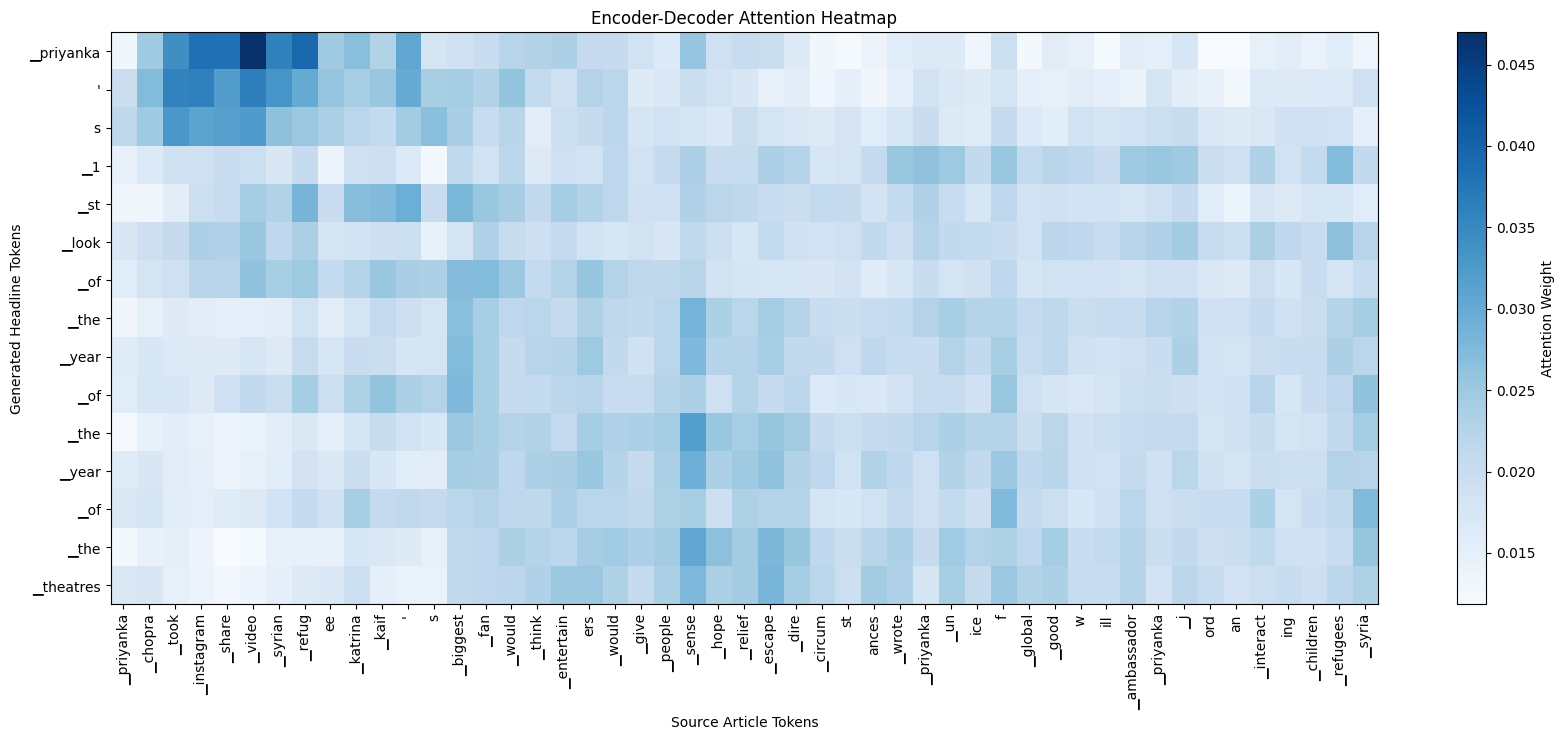

In [86]:
# 추가 실험 2. Attention Heatmap

idx = 0

generated, maps, generated_ids = generate(
    models["Attention"],
    X_test[idx:idx+1],
    return_ids=True
)

source_ids = [
    token_id
    for token_id in X_test[idx].tolist()
    if token_id != PAD
]

source_words = [
    src_index_to_word.get(token_id, "<UNK>")
    for token_id in source_ids
]

generated_words = [
    sp.id_to_piece(idx)
    for idx in generated_ids[0]
]

print("원본 기사:", test_df.iloc[idx]["text"])
print("실제 헤드라인:", test_df.iloc[idx]["headlines"])
print("생성 요약:", generated[0])

if len(maps[0]) > 0:

    attention_matrix = np.array(
        maps[0]
    )[:, :len(source_words)]

    plt.figure(
        figsize=(
            max(12, len(source_words) * 0.35),
            max(4, len(generated_words) * 0.5)
        )
    )

    plt.imshow(
        attention_matrix,
        aspect="auto",
        cmap="Blues"
    )

    plt.xticks(
        range(len(source_words)),
        source_words,
        rotation=90
    )

    plt.yticks(
        range(len(generated_words)),
        generated_words
    )

    plt.xlabel("Source Article Tokens")
    plt.ylabel("Generated Headline Tokens")
    plt.title("Encoder-Decoder Attention Heatmap")

    plt.colorbar(label="Attention Weight")
    plt.tight_layout()
    plt.show()

else:
    print("생성된 일반 토큰이 없어 Heatmap을 표시할 수 없습니다.")

In [87]:
# 추가 실험 3-1. 헤드라인 핵심 단어 비교

def keyword_recall(reference, prediction):

    ref_words = set(
        preprocess(reference, True)
    )

    pred_words = set(
        preprocess(prediction, True)
    )

    matched = ref_words & pred_words

    recall = (
        len(matched) / len(ref_words)
        if ref_words else 0
    )

    return recall, ", ".join(sorted(matched))


qualitative_rows = []

for idx in range(min(5, len(comparison_df))):

    row = comparison_df.iloc[idx]

    for method in ["Attention", "Summa + Fallback"]:

        recall, matched = keyword_recall(
            row["Reference"],
            row[method]
        )

        qualitative_rows.append({
            "Sample": idx + 1,
            "Method": method,
            "Article": row["Article"],
            "Reference": row["Reference"],
            "Prediction": row[method],
            "Summa Success": row["Summa Success"],
            "Matched Keywords": matched,
            "Keyword Recall": round(recall, 4),
            "Grammar (1-3)": "",
            "Factuality (1-3)": "",
            "Comment": ""
        })

qualitative_df = pd.DataFrame(qualitative_rows)

with pd.option_context("display.max_colwidth", None):
    display(qualitative_df)

,Sample,Method,Article,Reference,Prediction,Summa Success,Matched Keywords,Keyword Recall,Grammar (1-3),Factuality (1-3),Comment
0,1,Attention,"Prime Minister Narendra Modi advised a group of senior IAS officers that they should not look at their work as just a duty, but an opportunity to make a positive transformation for governance in the country. ""Donât restrict yourself to files but go to the field to understand the true impact of decision making,"" Modi further said.",Use work as chance to transform governance: PM to IAS officers,pm modi is the best pm modi on pm modi's pm modi,False,pm,0.1250,,,
1,1,Summa + Fallback,"Prime Minister Narendra Modi advised a group of senior IAS officers that they should not look at their work as just a duty, but an opportunity to make a positive transformation for governance in the country. ""Donât restrict yourself to files but go to the field to understand the true impact of decision making,"" Modi further said.",Use work as chance to transform governance: PM to IAS officers,"Prime Minister Narendra Modi advised a group of senior IAS officers that they should not look at their work as just a duty, but an opportunity to make a positive transformation for governance in the country.",False,"governance, ias, officers, work",0.5000,,,
2,2,Attention,"AIADMK faction leader O Panneerselvam on Sunday offered â¹10,000 to anyone asking and getting a reply from Tamil Nadu Chief Minister K Palaniswami on ordering a judicial probe into the death of late CM J Jayalalithaa. He further added that his party's ""dharma yudh"" would continue till the ""mysterious knots"" in Jayalalithaa's death were not removed.",OPS offers â¹10K for getting TN CM to respond on Jaya's death,bjp leader's son's son's name in mp's son in,False,,0.0000,,,
3,2,Summa + Fallback,"AIADMK faction leader O Panneerselvam on Sunday offered â¹10,000 to anyone asking and getting a reply from Tamil Nadu Chief Minister K Palaniswami on ordering a judicial probe into the death of late CM J Jayalalithaa. He further added that his party's ""dharma yudh"" would continue till the ""mysterious knots"" in Jayalalithaa's death were not removed.",OPS offers â¹10K for getting TN CM to respond on Jaya's death,"AIADMK faction leader O Panneerselvam on Sunday offered â¹10,000 to anyone asking and getting a reply from Tamil Nadu Chief Minister K Palaniswami on ordering a judicial probe into the death of late CM J Jayalalithaa.",False,"cm, death, getting, k",0.4000,,,
4,3,Attention,"Madras High Court on Tuesday banned the use of pictures of living persons on ""banners, signboards, flex boards and so on"" across Tamil Nadu. The prohibition will also apply to individuals sponsoring the banners and flex boards. The court ruled this while hearing a woman's petition, seeking removal of a flag and a signboard for blocking entry into her property.","HC bans pics of living persons on banners, signboards in TN",hc bans use of drugs to be probed by hc,True,"bans, hc",0.2500,,,
5,3,Summa + Fallback,"Madras High Court on Tuesday banned the use of pictures of living persons on ""banners, signboards, flex boards and so on"" across Tamil Nadu. The prohibition will also apply to individuals sponsoring the banners and flex boards. The court ruled this while hearing a woman's petition, seeking removal of a flag and a signboard for blocking entry into her property.","HC bans pics of living persons on banners, signboards in TN","Madras High Court on Tuesday banned the use of pictures of living persons on ""banners, signboards, flex boards and so on"" across Tamil Nadu.",True,"banners, living, persons, signboards",0.5000,,,
6,4,Attention,"Amazon has introduced a feature in its app that lets users place items such as electronics, and home decor inside their home using augmented reality. Launched on iOS 11, it allows customers to overlay, move, and rotate the item in a live camera view mode. It can be activated by clicking on the camera icon in the app.",Amazon app le

## **8-2. 프로젝트 평가 및 회고**

### 1. 프로젝트 수행 목적

이번 프로젝트에서는 뉴스 기사 데이터를 활용하여 추상적 요약(Abstractive Summarization)과 추출적 요약(Extractive Summarization)을 구현하고, 두 방식의 특징과 성능 차이를 비교하고자 하였다.

기존 학습 내용에 따라 LSTM 기반 Seq2Seq 모델에 Attention Mechanism을 적용하였으며, Summa를 이용한 추출적 요약도 함께 수행하였다. 추가로 ROUGE 평가, Lead-1 기준 모델 비교, Attention Heatmap 시각화를 진행하였다.

특히 초기 모델에서 발생한 UNK 반복 생성 문제를 해결하기 위해 이전 프로젝트에서 학습했던 SentencePiece를 적용하고, 개선 전후의 결과를 비교하였다.

---

### 2. 데이터 전처리 및 실험 조건 평가

전체 98,401건의 뉴스 데이터를 대상으로 결측값 확인, 중복 제거, 텍스트 정규화 및 불용어 제거를 수행하였다. 전처리 이후 총 98,339건의 데이터를 확보하였으며, 이 중 30,000건을 추출하여 최종 실험에 사용하였다.

뉴스 기사에서는 날짜, 인원수, 금액, 비율 등의 정보가 중요한 경우가 많기 때문에 숫자와 일부 단위 기호를 유지하도록 전처리 방식을 구성하였다. 또한 부정 표현이 제거되어 문장의 의미가 달라지는 것을 방지하고자 주요 부정 표현을 유지하였다.

본문에는 불용어 제거를 적용하였지만, 헤드라인은 문장의 자연스러운 구성을 고려하여 불용어를 제거하지 않았다.

최대 시퀀스 길이는 임의로 설정하지 않고 학습 데이터의 토큰 길이 분포를 분석하여 결정하였다. 이후 SentencePiece를 적용하면서 토큰 길이가 달라졌기 때문에 길이 분포를 다시 분석하고 최대 길이를 재설정하였다.

**최종 실험 조건**

| 항목 | 설정 |
|---|---|
| 전체 실험 데이터 | 30,000건 |
| 학습 데이터 | 24,000건 |
| 검증 데이터 | 3,000건 |
| 테스트 데이터 | 3,000건 |
| Tokenizer | SentencePiece BPE |
| Vocabulary Size | 8,000 |
| Encoder 최대 길이 | 68 |
| Decoder 최대 생성 길이 | 17 |
| Embedding Dimension | 96 |
| LSTM Hidden Size | 128 |
| Batch Size | 64 |
| Epoch | 20 |
| Optimizer | AdamW |
| Learning Rate | 0.001 |
| Dropout | 0.2 |

단어사전과 SentencePiece 모델은 학습 데이터만을 이용하여 구축함으로써 검증 및 테스트 데이터가 학습 과정에 직접적으로 사용되지 않도록 하였다.

---

### 3. 초기 모델의 문제점 및 개선 과정

#### 3.1. UNK 반복 생성 문제

초기에는 단어의 등장 빈도를 기준으로 Vocabulary를 구축하고, 이를 Attention 기반 Seq2Seq 모델에 적용하였다.

학습 과정에서 Train Loss와 Validation Loss가 모두 감소하였지만, 실제 생성된 요약문에서는 `<UNK>` 토큰이 반복적으로 출력되는 문제가 발생하였다.

처음에는 학습 데이터와 Epoch가 부족한 것이 원인이라고 생각하였다. 이에 따라 학습 데이터를 4,800건에서 24,000건으로 확대하고 학습 횟수도 증가시켰다.

그러나 일부 영어 단어가 생성되기 시작했음에도 UNK 반복 문제는 지속되었다. 단순히 학습량을 증가시키는 것만으로는 문제를 해결하기 어렵다고 판단하였다.

#### 3.2. 문제 원인 분석

기존 단어사전은 정해진 Vocabulary 크기 내에서 빈도가 높은 단어를 등록하고, 나머지 단어는 UNK로 변환하는 방식이었다.

뉴스 데이터에는 인명, 지명, 기업명과 같이 등장 빈도가 낮은 단어가 많다. 따라서 서로 다른 단어가 동일한 UNK 토큰으로 변환될 수 있으며, 이러한 토큰이 Decoder의 학습 정답에 포함되는 구조가 반복 생성의 원인 중 하나라고 판단하였다.

또한 Greedy Decoding 방식에서는 이전 단계에서 생성한 토큰을 다음 단계의 입력으로 사용하므로, UNK가 한 번 생성되면 이후에도 반복될 가능성이 있다고 생각하였다.

#### 3.3. SentencePiece를 이용한 개선

이전 프로젝트인 '멋진 단어사전 만들기'에서 학습한 SentencePiece를 이번 문제 해결에 활용하였다.

기존 단어 단위의 토큰화 방식 대신 BPE 기반 서브워드 토큰화를 적용하였다. 추가로 Byte Fallback을 사용하여 학습되지 않은 문자도 바이트 단위로 표현할 수 있도록 구성하였다.

이를 통해 단어사전에 등록되지 않은 단어도 여러 개의 작은 토큰으로 분리하여 표현할 수 있도록 개선하였다.

| 구분 | 기존 방식 | 개선 방식 |
|---|---|---|
| 토큰화 | Word-level | SentencePiece BPE |
| 희귀 단어 처리 | UNK 변환 | 서브워드 분리 |
| 미등록 문자 처리 | UNK 변환 가능 | Byte Fallback |
| 요약문 복원 | 단어 연결 | SentencePiece Decoding |

#### 3.4. UNK 개선 결과

SentencePiece 적용 이후 학습, 검증 및 테스트 데이터에 포함된 미등록 토큰의 비율을 확인하였다.

| 데이터 구분 | Encoder UNK 비율 | Decoder Target UNK 비율 |
|---|---:|---:|
| Train | 0.00% | 0.00% |
| Validation | 0.00% | 0.00% |
| Test | 0.00% | 0.00% |

생성된 요약문의 UNK 비율도 별도로 확인하였다.

| 구분 | 생성 UNK 비율 |
|---|---:|
| 기존 Word-level 모델 | 56.90% |
| 개선 SentencePiece 모델 | 0.00% |

SentencePiece를 적용한 데이터에서는 UNK가 발생하지 않았으며, 생성 요약문을 대상으로 한 검증에서도 UNK가 검출되지 않았다.

단순히 추론 과정에서 UNK의 출력을 강제로 제한한 것이 아니라, 토큰화 방식을 변경하여 희귀 단어를 표현할 수 있도록 개선하였다는 점에서 의미가 있다고 생각한다.

다만 UNK가 제거되었다고 해서 모델이 뉴스의 의미를 정확하게 이해하는 것은 아니므로, 실제 생성된 요약문의 품질도 함께 평가하였다.

---

### 4. 추상적 요약 모델의 학습 결과

최종적으로 SentencePiece 기반 데이터를 이용하여 Attention Seq2Seq 모델을 20 Epoch 동안 학습하였다.

| Epoch | Train Loss | Validation Loss |
|---:|---:|---:|
| 1 | 7.2539 | 6.9243 |
| 5 | 5.9988 | 5.9587 |
| 10 | 5.2592 | 5.4863 |
| 15 | 4.8484 | 5.2805 |
| 20 | 4.5544 | 5.1768 |

학습이 진행됨에 따라 Train Loss와 Validation Loss가 모두 지속적으로 감소하였다. Validation Loss가 가장 낮았던 20 Epoch의 모델을 최종 추론에 사용하였다.

학습 후반부에는 Train Loss와 Validation Loss의 차이가 점차 증가하였지만, Validation Loss 자체가 상승하지는 않았다. 따라서 현재 학습 범위에서는 명확한 과적합이 발생하였다고 판단하기 어렵다.

실제 생성 결과에서는 이전과 달리 UNK 대신 영어 단어들이 생성되었으며, 일부 기사에서는 실제 헤드라인에 포함된 인물이나 핵심 단어가 나타났다.

그러나 원문과 관련 없는 단어가 생성되거나 동일한 표현이 반복되는 문제는 여전히 존재하였다. 이를 통해 토큰화 문제의 해결과 문맥 이해 능력의 확보는 서로 다른 문제라는 점을 확인하였다.

---

### 5. 추상적 요약과 추출적 요약의 성능 비교

#### 5.1. ROUGE를 이용한 정량 평가

단순히 생성된 문장을 확인하는 것 외에도 두 요약 방식의 성능을 정량적으로 비교하고자 ROUGE-1, ROUGE-2, ROUGE-L을 계산하였다.

추가로 뉴스 기사의 첫 문장을 선택하는 Lead-1을 기준 모델로 설정하였다.

테스트 데이터 중 동일한 뉴스 기사 200건을 대상으로 평가한 결과는 다음과 같다.

| 요약 방식 | ROUGE-1 | ROUGE-2 | ROUGE-L | 평균 단어 수 |
|---|---:|---:|---:|---:|
| Attention + SentencePiece | 0.1368 | 0.0198 | 0.1257 | 10.68 |
| Summa + Fallback | 0.3280 | 0.1321 | 0.2734 | 24.03 |
| Lead-1 | 0.4028 | 0.1824 | 0.3435 | 25.60 |

추상적 요약 모델은 추출적 요약보다 낮은 ROUGE 점수를 나타냈지만, 평균적으로 더 짧은 요약문을 생성하였다.

전체 실험에서는 Lead-1이 가장 높은 ROUGE 점수를 기록하였다. 처음에는 문장 간 중요도를 분석하는 Summa가 단순히 첫 문장을 선택하는 방식보다 높은 성능을 보일 것으로 예상하였다.

그러나 실제 결과는 예상과 달랐다. 뉴스 기사에서는 중요한 내용을 앞부분에 배치하는 경우가 많기 때문에 이러한 데이터의 특성이 Lead-1의 성능에 영향을 미쳤을 가능성이 있다고 판단하였다.

#### 5.2. Summa 요약 성공률 분석

전체 200건의 뉴스 기사 중 Summa가 자체적으로 요약문을 생성한 경우는 147건으로, 73.5%의 성공률을 나타냈다.

나머지 53건에서는 요약문을 생성하지 못하여 Lead-1 방식으로 대체하였다.

Summa가 자체적으로 요약에 성공한 147건만을 대상으로 동일한 조건에서 다시 비교하였다.

| 요약 방식 | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| Attention + SentencePiece | 0.1397 | 0.0232 | 0.1290 |
| Summa | 0.3136 | 0.1259 | 0.2658 |
| Lead-1 | 0.4154 | 0.1944 | 0.3612 |

Summa가 정상적으로 요약문을 생성한 기사만 비교하였을 때도 Lead-1의 성능이 높게 나타났다.

따라서 이번 결과가 단순히 Summa의 요약 실패 사례 때문에 발생한 것은 아니라는 점을 확인하였다.

---

### 6. 문법 완성도 및 핵심 단어 포함 여부 비교

ROUGE 점수만으로는 실제 요약문의 문법적인 완성도나 사실관계를 충분히 평가하기 어렵다고 판단하였다.

이에 따라 동일한 뉴스 기사 5건을 대상으로 추상적 요약과 추출적 요약의 실제 결과를 비교하였다.

문법 완성도는 다음 기준에 따라 정성적으로 평가하였다.

| 점수 | 평가 기준 |
|---|---|
| 1점 | 문장 구조가 불완전하여 의미 파악이 어려움 |
| 2점 | 일부 표현이 어색하지만 대략적인 의미 파악이 가능함 |
| 3점 | 문법적으로 자연스럽고 의미 전달이 가능함 |

핵심 단어 포함률은 실제 헤드라인에서 불용어를 제외한 단어 중 생성 요약문에 포함된 단어의 비율로 계산하였다.

| 뉴스 주제 | 추상적 요약 문법 | 추출적 요약 문법 | 추상적 요약 핵심 단어 포함률 | 추출적 요약 핵심 단어 포함률 |
|---|---:|---:|---:|---:|
| Modi 총리의 행정 개혁 관련 발언 | 2/3 | 3/3 | 12.50% | 50.00% |
| 인도 정치인의 보상금 제안 | 1/3 | 3/3 | 0.00% | 40.00% |
| 법원의 인물 사진 사용 금지 | 2/3 | 3/3 | 25.00% | 50.00% |
| Amazon의 증강현실 기능 | 3/3 | 3/3 | 0.00% | 10.00% |
| 화산 활동과 과거 지구온난화 | 1/3 | 3/3 | 0.00% | 11.11% |

첫 번째와 두 번째 기사에서는 Summa가 자체적으로 요약문을 생성하지 못하여 Lead-1을 적용하였다.

**Modi 총리 관련 기사**

추상적 요약 모델은 `pm modi`라는 관련 단어를 생성하였지만 동일한 표현을 반복하였으며, 실제 기사의 행정 개혁에 관한 내용을 전달하지 못하였다.

반면 추출적 요약은 행정 업무를 국가의 긍정적인 변화에 기여할 기회로 바라보라는 원문의 내용을 유지하였다.

**법원의 인물 사진 사용 금지 기사**

추상적 요약에서는 `hc bans`라는 실제 헤드라인과 관련된 표현을 생성하였다. 그러나 인물 사진의 사용을 금지한다는 내용을 마약 사용과 관련된 내용으로 잘못 생성하였다.

일부 핵심 단어가 일치하더라도 문장 전체의 의미가 달라질 수 있다는 사례이다.

**Amazon의 증강현실 기능 관련 기사**

추상적 요약 모델은 Google Maps와 암호화폐에 관한 문장을 생성하였다. 문장 구조 자체는 비교적 자연스러웠지만, 실제 기사와는 전혀 다른 내용을 전달하였다.

추출적 요약은 원문에 있는 문장을 선택하였으나 증강현실 기능 자체보다 카메라 아이콘을 이용한 실행 방법에 관한 문장을 선택하였다. 사실관계는 유지하였지만 핵심 내용이 충분히 포함되지는 않았다.

이러한 사례를 비교하면서 문법적으로 자연스러운 문장이 반드시 올바른 요약문인 것은 아니라는 점을 알 수 있었다.

또한 추출적 요약은 원문의 사실을 그대로 유지하는 데 유리하지만, 어떤 문장을 선택하는지에 따라 핵심 정보가 누락될 수 있음을 확인하였다.

---

### 7. Attention Heatmap 분석

Attention Mechanism의 작동 특성을 확인하기 위해 요약문 생성 단계별로 입력 토큰에 부여되는 Attention 가중치를 시각화하였다.

Heatmap의 가로축은 뉴스 본문의 서브워드 토큰으로 구성하였으며, 세로축은 Decoder가 생성한 서브워드 토큰으로 구성하였다.

이를 통해 요약문을 생성하는 각 단계에서 입력 문장의 여러 위치에 서로 다른 가중치가 부여되는 것을 확인하였다.

다만 현재 모델의 생성 문장에는 사실 오류와 반복 표현이 포함되어 있으므로, 높은 Attention 가중치가 부여된 부분이 반드시 올바른 요약문 생성에 기여하였다고 해석하기는 어렵다.

Attention의 실제 성능 개선 효과를 검증하려면 동일한 조건에서 Attention을 적용하지 않은 Seq2Seq 모델과 비교할 필요가 있다고 생각한다.

---

### 8. 프로젝트 수행을 통해 느낀 점과 깨달은 점

#### 8.1. 학습 지표와 실제 모델 성능의 차이

이번 프로젝트에서 가장 크게 깨달은 부분은 Loss가 감소한다고 해서 모델이 반드시 원하는 결과를 생성하는 것은 아니라는 점이다.

초기에는 Train Loss와 Validation Loss가 모두 감소하는 것을 보고 모델 학습이 잘 진행되고 있다고 생각하였다. 그러나 실제로 요약문을 생성해 보니 UNK가 반복적으로 출력되었으며, 의미 있는 결과를 얻지 못하였다.

이전 감성분석 프로젝트에서는 Accuracy와 F1-score를 통해 모델의 분류 성능을 비교할 수 있었지만, 텍스트 생성 문제에서는 문장의 의미, 문법, 사실관계까지 함께 고려해야 한다는 차이가 있었다.

모델을 평가할 때 학습 그래프만 확인하는 것이 아니라 실제 사용 환경에서 어떤 결과가 나오는지 직접 확인하는 과정이 중요하다고 느꼈다.

#### 8.2. 이전 학습 내용을 활용한 문제 해결

UNK 문제가 지속되었을 때 단순히 학습 데이터와 Epoch를 증가시키는 방법만 생각하였다.

그러나 학습량을 증가시켜도 문제가 해결되지 않는 것을 확인하면서 모델 구조뿐 아니라 입력 데이터가 어떤 방식으로 표현되는지도 검토할 필요가 있다고 생각하였다.

이 과정에서 이전 프로젝트에서 학습한 SentencePiece를 적용하였고, 실제로 UNK 문제를 개선할 수 있었다.

각 프로젝트에서 배운 기술이 독립적으로 존재하는 것이 아니라, 새로운 문제를 해결하는 과정에서 서로 연결되어 활용될 수 있다는 점이 인상적이었다.

#### 8.3. 복잡한 모델이 항상 좋은 결과를 내는 것은 아니다

이번 실험에서는 Attention 기반 Seq2Seq 모델과 Summa보다 단순히 첫 문장을 선택하는 Lead-1이 높은 ROUGE 점수를 기록하였다.

처음에는 복잡한 모델이나 알고리즘을 적용하면 더 좋은 결과를 얻을 수 있을 것으로 생각하였지만, 실제 실험에서는 데이터의 특성과 문제의 목적에 따라 단순한 방법이 더 효과적일 수도 있었다.

따라서 새로운 기술을 적용하는 것 자체보다 기존의 단순한 방식과 비교하여 실제로 어떤 개선이 이루어졌는지를 검증하는 과정이 중요하다고 생각한다.

#### 8.4. 생성형 AI의 한계에 대한 이해

SentencePiece를 적용한 이후 UNK 문제는 개선되었지만, 모델이 원문에 없는 인물이나 사건을 생성하는 문제가 발생하였다.

이러한 결과를 통해 문법적으로 자연스러운 문장을 생성하는 능력과 정확한 사실을 전달하는 능력이 서로 다를 수 있다는 점을 이해하였다.

특히 생성형 AI를 뉴스 요약이나 정보 전달에 활용할 때는 출력 문장이 자연스러운지만 확인하는 것이 아니라, 원본 정보와 일치하는지 검증하는 과정도 필요하다고 생각한다.

---

### 9. 실험의 한계 및 개선 방향

이번 프로젝트에서는 SentencePiece 적용을 통해 UNK 문제를 개선하였으며, 추상적 요약 모델의 생성 결과도 이전보다 개선되었다.

그러나 실제 기사의 핵심 내용을 정확하게 전달하는 데에는 여전히 한계가 있었다. 또한 SentencePiece 적용과 Epoch 증가를 동시에 진행하였기 때문에 각각의 변경 사항이 성능 개선에 어느 정도 영향을 미쳤는지는 구분하기 어렵다.

향후에는 다음과 같은 방향으로 개선하고자 한다.

| 개선 항목 | 개선 방향 |
|---|---|
| 학습 데이터 | 전체 뉴스 데이터 활용 및 데이터 규모별 성능 비교 |
| 학습 조건 | 추가 Epoch 학습 및 Validation Loss 기반 과적합 확인 |
| 데이터 전처리 | 일부 깨진 문자 인코딩 복구 및 숫자 정보 보존 개선 |
| 토큰화 | 동일한 학습 조건에서 Word-level과 SentencePiece 비교 |
| 문장 생성 | Greedy Decoding과 Beam Search 비교 |
| 반복 생성 | 동일한 단어 및 표현의 반복을 제한하는 방법 검토 |
| Attention | Attention 적용 여부에 따른 성능 비교 |
| 사실 오류 | 원문의 고유명사와 수치를 직접 활용할 수 있는 Pointer-Generator 방식 검토 |
| 모델 구조 | 향후 Transformer 및 사전학습 요약 모델과 비교 |
| 성능 평가 | ROUGE 외 문법 완성도와 사실 일치성에 대한 평가 확대 |

특히 데이터 규모, 토큰화 방식, 학습 횟수 등의 조건을 한 번에 변경하기보다는 각각의 변수를 구분하여 실험하는 것이 필요하다고 생각한다.

이를 통해 단순히 성능이 향상되었다는 결과에서 나아가 어떤 요소가 실제 성능 개선에 영향을 미쳤는지 분석할 수 있을 것으로 판단된다.

---

### 10. 최종 결론

본 프로젝트에서는 뉴스 데이터의 전처리부터 단어사전 구축, Attention 기반 Seq2Seq 모델 학습, 추론 및 요약 성능 평가까지 텍스트 요약의 전체 과정을 구현하였다.

초기 모델에서는 UNK 반복 생성 문제가 발생하였으며, 학습 데이터를 확대하였음에도 문제가 지속되었다. 이후 SentencePiece BPE와 Byte Fallback을 적용하여 미등록 토큰 문제를 개선하였다.

최종 추상적 요약 모델은 ROUGE-1 0.1368, ROUGE-2 0.0198, ROUGE-L 0.1257을 기록하였다.

추출적 요약과의 비교에서는 Lead-1이 ROUGE-1 0.4028, ROUGE-2 0.1824, ROUGE-L 0.3435로 가장 높은 성능을 나타냈다.

추상적 요약 모델의 품질은 여전히 추출적 요약보다 낮았으며, 원문과 다른 사실을 생성하거나 동일한 표현을 반복하는 문제도 확인하였다.

이번 프로젝트를 통해 원하는 결과를 얻지 못했을 때 단순히 모델을 다시 학습시키는 것보다, 데이터 전처리와 토큰화, 모델 구조, 추론 방식 등 여러 요소를 구분하여 문제의 원인을 분석하는 과정이 중요하다는 점을 배웠다.

최종 모델이 완성도 높은 뉴스 요약문을 생성하는 수준까지 도달하지는 못하였지만, 문제를 발견하고 이전에 학습한 기술을 적용하여 개선한 뒤 정량적·정성적 평가를 통해 결과를 검증하였다는 점에서 의미 있는 프로젝트였다고 생각한다.

## **8-3. 프로젝트 제출**

### 루브릭

아래의 기준을 바탕으로 프로젝트를 평가합니다.<br>
<br>

|평가문항|상세기준|
|---|---|
|<br>**1. Abstractive 모델 구성을 위한 텍스트 전처리<br> 단계가 체계적으로 진행되었다.**<br><br>|<br>분석단계, 정제단계, 정규화와 불용어 제거, 데이터셋 분리, 인코딩 과정이 빠짐없이<br> 체계적으로 진행되었다.<br><br>|
|<br>**2. 텍스트 요약모델이 성공적으로 학습되었음을<br> 확인하였다.**<br><br>|<br>모델 학습이 진행되면서 train loss와 validation loss가 감소하는 경향을 그래프를 통해<br> 확인했으며, 실제 요약문에 있는 핵심 단어들이 요약 문장 안에 포함되었다.<br><br>|
|<br>**3. Extractive 요약을 시도해 보고 Abstractive<br> 요약 결과과 함께 비교해 보았다.**<br><br>|<br>두 요약 결과를 문법완성도 측면과 핵심단어 포함 측면으로 나누어 비교하고 분석 결과를<br> 표로 정리하여 제시하였다.<br><br>|

### 프로젝트 제출

프로젝트 제출 방법 안내